# 🏠 House Price Prediction — Regression with Supervised Learning
**Practical Exam | Supervised Learning — Set A**

Dataset: Ames Housing (`train.csv`, 1,460 rows, 79 features). Target: `SalePrice`.

# 🧠 Step 1: Problem Framing & Theory Notes

**1. What is Regression? Difference from Classification?**
- Regression predicts a **continuous number**. Classification predicts a **category**.
- Regression examples (India): predicting EMI amount at HDFC, predicting crop yield in Maharashtra.
- Classification examples: loan default (Yes/No), spam or not spam.

**2. Simple vs Multiple vs Regularised Regression**
- **Simple Linear Regression:** one input feature (price from area only).
- **Multiple Linear Regression:** many input features.
- **Ridge / Lasso:** multiple regression with a penalty on coefficients. Ridge (L2) shrinks them, Lasso (L1) can make some exactly zero.

**3. Overfitting and Underfitting**
- **Overfitting:** model learns the training data too well (noise), so train score is high but test score is low.
- **Underfitting:** model is too simple, so both train and test scores are low.
- L1 / L2 add a penalty on big coefficients, so the model becomes simpler and generalises better.

**4. RMSE, MAE and R²**
- **MAE** = average of absolute errors. **RMSE** = square root of average squared errors. **R²** = how much variance of the target the model explains.
- Prefer **RMSE** when big errors are very costly, because squaring punishes big mistakes more.

**5. Cross-Validation (k-Fold)**
- Data is split into k folds. Each fold is used once for testing and the rest for training. The final score is the average of k scores.
- It is better than one train-test split because the score does not depend on one lucky split and all data is used.

# 📂 Step 2: Dataset Loading & EDA
### 2.1 Load & Understand the Dataset

In [63]:
import pandas as pd
import numpy as np

df = pd.read_csv('train.csv')
print(df.shape)

(1460, 81)


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [65]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [66]:
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(exclude='number').columns
print("Numerical columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))
print("Columns with missing values:", (df.isnull().sum() > 0).sum())

Numerical columns: 38
Categorical columns: 43
Columns with missing values: 19


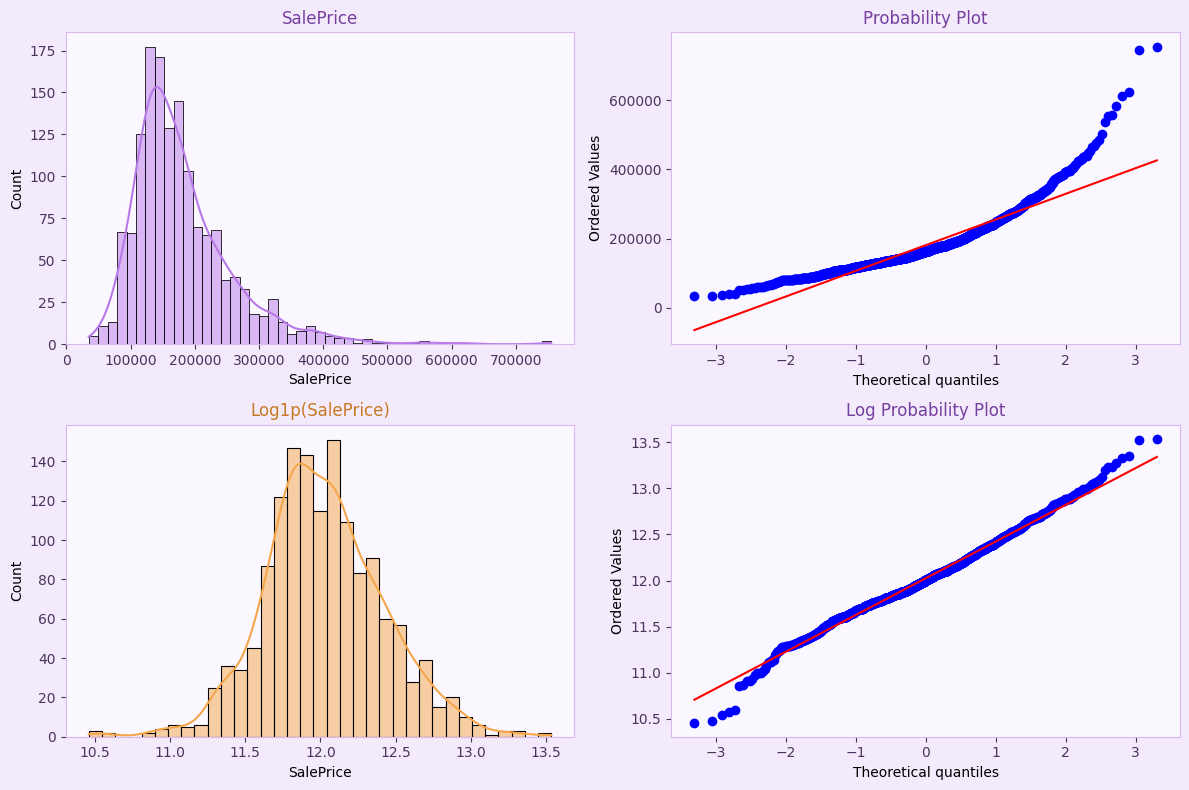

Skew before: 1.88
Skew after: 0.12


In [67]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats



fig, ax = plt.subplots(2, 2, figsize=(12, 8))
fig.patch.set_facecolor('#F3EAFB')

for a in ax.flat:
    a.set_facecolor('#FBF7FF')
    a.tick_params(colors='#49345D')
    for spine in a.spines.values():
        spine.set_color('#D8B8EF')

sns.histplot(df['SalePrice'], kde=True, color='#B879E8', ax=ax[0, 0])
ax[0, 0].set_title('SalePrice', color='#7540A0')

stats.probplot(df['SalePrice'], plot=ax[0, 1])
ax[0, 1].set_title('Probability Plot', color='#7540A0')

sns.histplot(np.log1p(df['SalePrice']), kde=True, color='#F5A64A', ax=ax[1, 0])
ax[1, 0].set_title('Log1p(SalePrice)', color='#C77A24')

stats.probplot(np.log1p(df['SalePrice']), plot=ax[1, 1])
ax[1, 1].set_title('Log Probability Plot', color='#7540A0')

plt.tight_layout()
plt.show()

print("Skew before:", round(df['SalePrice'].skew(), 2))
print("Skew after:", round(np.log1p(df['SalePrice']).skew(), 2))


**Observation:** `SalePrice` is **not normally distributed**. It has a long right tail (skewness 1.88) and the Q-Q plot bends away from the line. After `log1p` the skewness becomes 0.12 and the plot is almost a straight line, so I use `log1p(SalePrice)` as the target.

### 2.2 Univariate Analysis

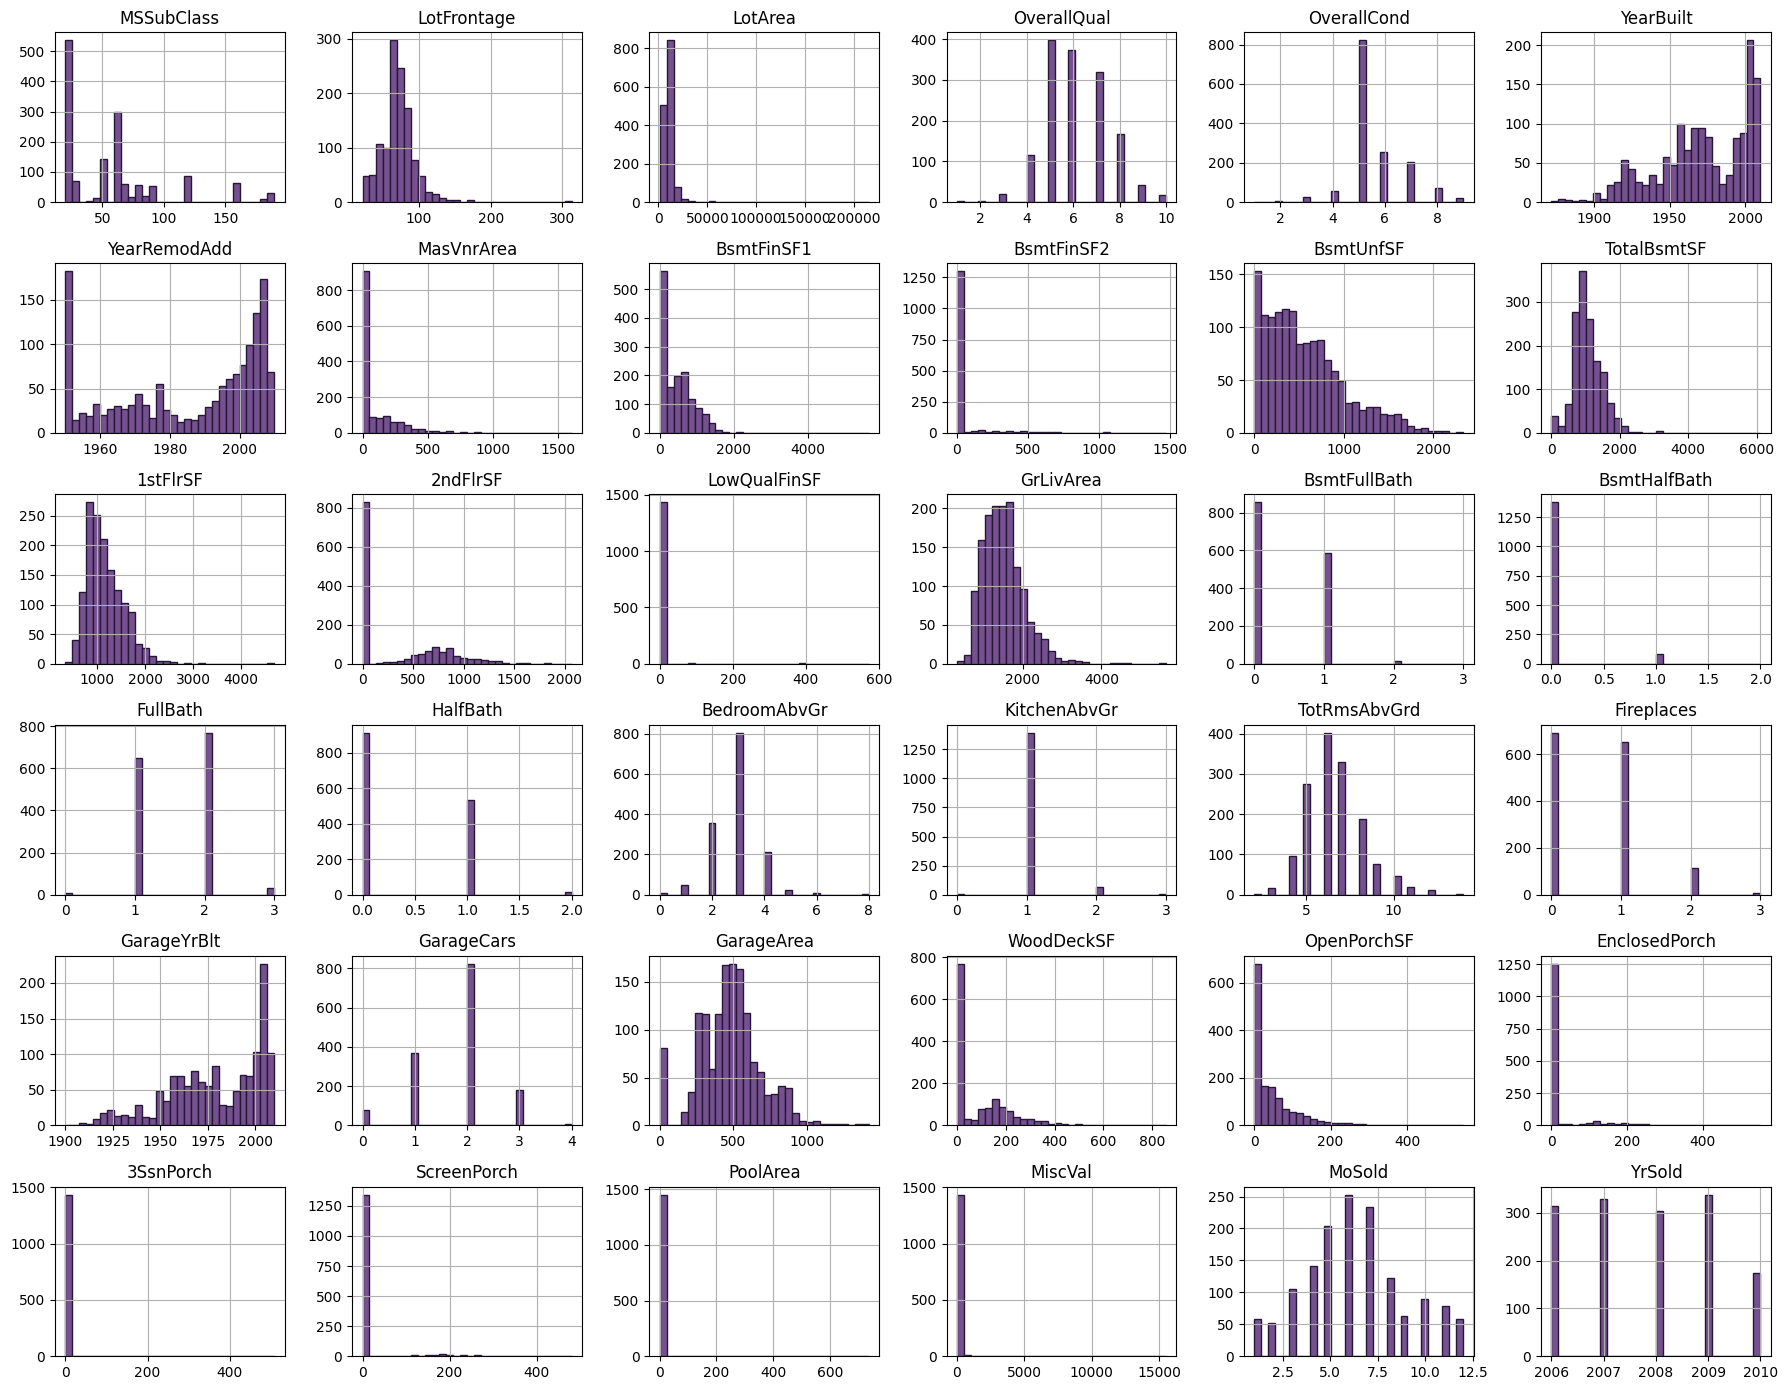

In [68]:
num_features = [c for c in num_cols if c not in ['Id', 'SalePrice']]
df[num_features].hist(bins=30, figsize=(18, 14), color='#76518F', edgecolor='#261638')
plt.tight_layout()
plt.show()

In [69]:
# top 5 skewed columns
df[num_features].skew().sort_values(ascending=False).head(5)

MiscVal         24.476794
PoolArea        14.828374
LotArea         12.207688
3SsnPorch       10.304342
LowQualFinSF     9.011341
dtype: float64

**Top 5 skewed columns:** `MiscVal`, `PoolArea`, `LotArea`, `3SsnPorch`, `LowQualFinSF`. Most houses have 0 in these columns and only a few have very big values.

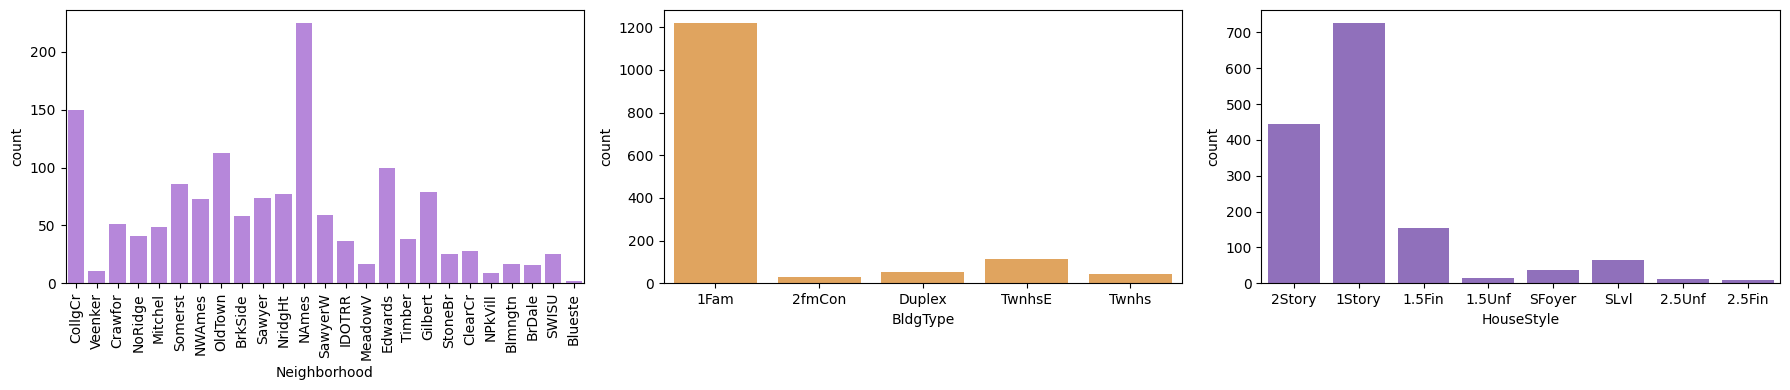

In [70]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

sns.countplot(x='Neighborhood', data=df, ax=ax[0], color='#B879E8')
ax[0].tick_params(axis='x', rotation=90)

sns.countplot(x='BldgType', data=df, ax=ax[1], color='#F5A64A')

sns.countplot(x='HouseStyle', data=df, ax=ax[2], color='#8E63C7')

plt.tight_layout()
plt.show()

### 2.3 Bivariate Analysis

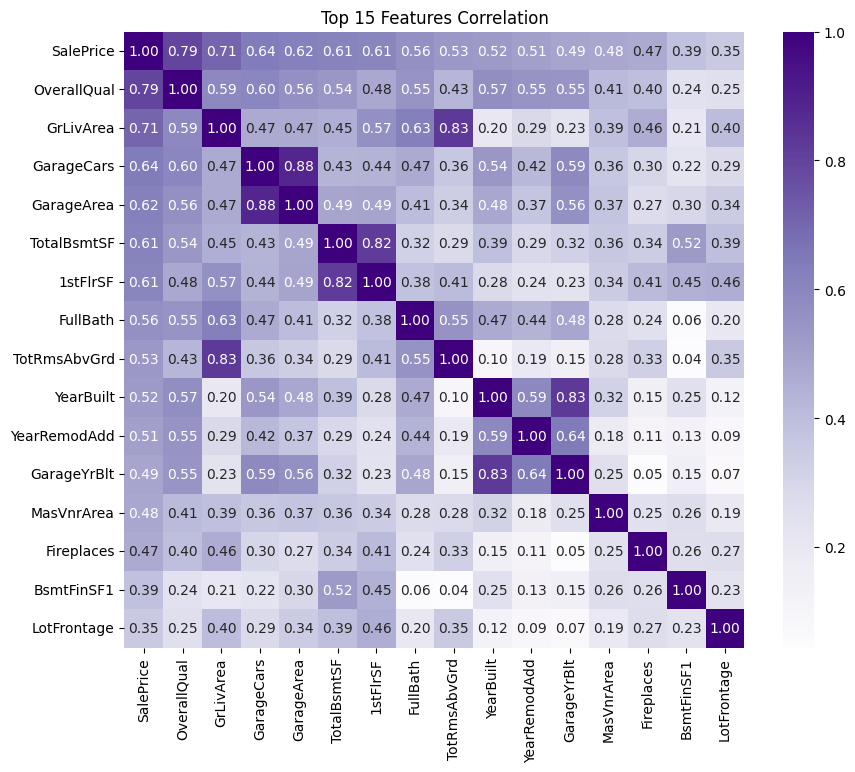

In [71]:
# Heatmap of top 15 features correlated with SalePrice
corr = df.corr(numeric_only=True)
top15 = corr['SalePrice'].abs().sort_values(ascending=False).head(16).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top15].corr(), annot=True, fmt='.2f', cmap='Purples')

plt.title('Top 15 Features Correlation')
plt.show()

**Observation:** `OverallQual` (0.79) and `GrLivArea` (0.71) have the strongest correlation with `SalePrice`, then `GarageCars` (0.64), `GarageArea` (0.62) and `TotalBsmtSF` (0.61).

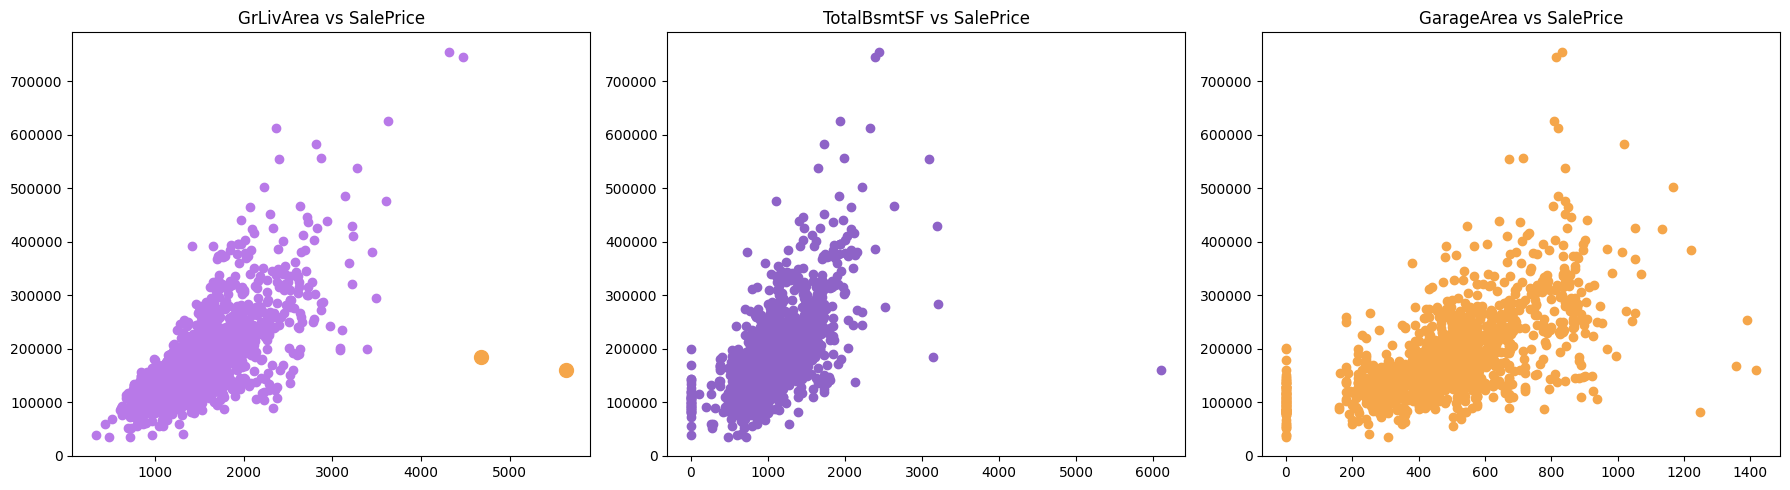

In [72]:
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(df['GrLivArea'], df['SalePrice'], color='#B879E8')
ax[0].scatter(outliers['GrLivArea'], outliers['SalePrice'],
              color='#F5A64A', s=100)
ax[0].set_title('GrLivArea vs SalePrice')

ax[1].scatter(df['TotalBsmtSF'], df['SalePrice'], color='#8E63C7')
ax[1].set_title('TotalBsmtSF vs SalePrice')

ax[2].scatter(df['GarageArea'], df['SalePrice'], color='#F5A64A')
ax[2].set_title('GarageArea vs SalePrice')

plt.tight_layout()
plt.show()

In [73]:
# the outlier rows
outliers[['Id', 'GrLivArea', 'SalePrice']]

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


**Observation:** All three features have a positive relationship with `SalePrice`. **Outliers:** Id 524 (4,676 sq.ft., $184,750) and Id 1299 (5,642 sq.ft., $160,000) have a very large area but a low price.

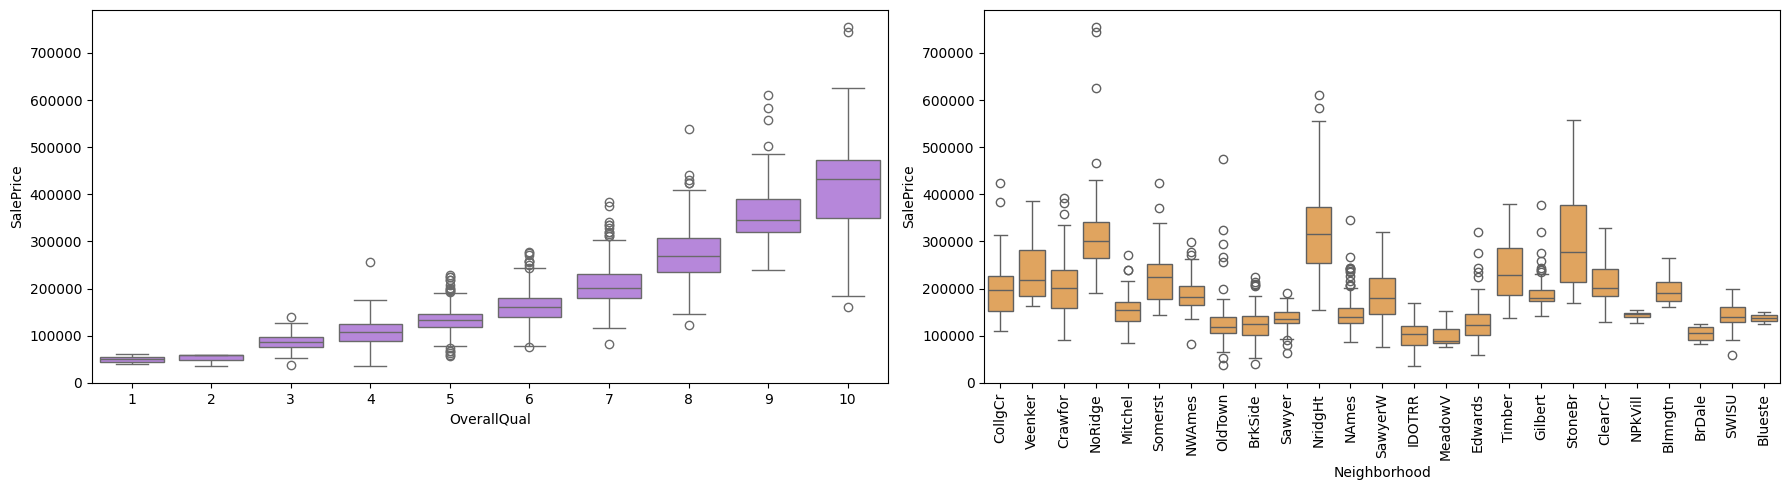

Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Name: SalePrice, dtype: float64


In [74]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))

sns.boxplot(x='OverallQual', y='SalePrice', data=df,
            ax=ax[0], color='#B879E8')

sns.boxplot(x='Neighborhood', y='SalePrice', data=df,
            ax=ax[1], color='#F5A64A')

ax[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

print(df.groupby('Neighborhood')['SalePrice'].median()
      .sort_values(ascending=False).head(3))

**Observation:** The price increases with every `OverallQual` level. **`NridgHt`** is the priciest neighborhood (median $315,000), then `NoRidge` and `StoneBr`.

# 🔧 Step 3: Data Preprocessing & Feature Engineering
### 3.1 Handle Missing Values

In [75]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)

PoolQC          99.52
MiscFeature     96.30
Alley           93.77
Fence           80.75
MasVnrType      59.73
FireplaceQu     47.26
LotFrontage     17.74
GarageType       5.55
GarageYrBlt      5.55
GarageFinish     5.55
GarageQual       5.55
GarageCond       5.55
BsmtExposure     2.60
BsmtFinType2     2.60
BsmtQual         2.53
BsmtCond         2.53
BsmtFinType1     2.53
MasVnrArea       0.55
Electrical       0.07
dtype: float64

In [76]:
# drop columns with more than 80% missing (also drop Id and GarageYrBlt)
drop_cols = list(missing_pct[missing_pct > 80].index)
print("Dropped (>80% missing):", drop_cols)
df = df.drop(columns=drop_cols + ['Id', 'GarageYrBlt'])

# categorical columns where NaN means 'None'
none_cols = ['MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
df[none_cols] = df[none_cols].fillna('None')

# numerical columns where NaN means 0
zero_cols = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'GarageArea', 'GarageCars']
df[zero_cols] = df[zero_cols].fillna(0)

# remaining: LotFrontage -> median, Electrical -> most common value
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

print("Missing values left:", df.isnull().sum().sum())

Dropped (>80% missing): ['Alley', 'PoolQC', 'Fence', 'MiscFeature']
Missing values left: 0


**What I did:** dropped the 4 columns with more than 80% missing values (`PoolQC`, `MiscFeature`, `Alley`, `Fence`), filled "not present" columns with `'None'` / 0, and filled `LotFrontage` with the median. (`PoolQC` and `Fence` are also in the "fill with None" list of the question, but they are more than 80% missing, so I dropped them.)

### 3.2 Outlier Removal

In [77]:
print("Before:", df.shape)
df = df[~((df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000))]
print("After :", df.shape)

Before: (1460, 75)
After : (1458, 75)


**Why outliers harm a linear model:** linear regression minimises squared error, so far-away points have a big pull on the line. These 2 houses have a huge area but a low price, so they would pull the line down and the model would learn a wrong relationship between area and price for normal houses.

### 3.3 Feature Engineering

In [78]:
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['HouseAge'] = df['YrSold'] - df['YearBuilt']
df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
df['HasPool'] = (df['PoolArea'] > 0).astype(int)

df[['TotalSF', 'HouseAge', 'RemodAge', 'HasGarage', 'HasPool']].head()

,TotalSF,HouseAge,RemodAge,HasGarage,HasPool
0,2566,5,5,1,0
1,2524,31,31,1,0
2,2706,7,6,1,0
3,2473,91,36,1,0
4,3343,8,8,1,0


### 3.4 Encoding & Scaling

In [79]:
# ordinal encoding of quality columns
quality = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu']
for col in ordinal_cols:
    df[col] = df[col].map(quality)

df[ordinal_cols].head()

,ExterQual,KitchenQual,BsmtQual,FireplaceQu
0,4,4,4,0
1,3,3,4,3
2,4,4,4,3
3,3,4,3,4
4,4,4,4,3


In [80]:
# log1p on skewed numerical columns (skewness > 0.75), quality columns are skipped
flag_cols = ['HasGarage', 'HasPool']
num_cols = [c for c in df.select_dtypes(include='number').columns if c not in flag_cols + ['SalePrice']]

skewed = [c for c in num_cols if c not in ordinal_cols and df[c].skew() > 0.75 and df[c].min() >= 0]
df[skewed] = np.log1p(df[skewed])
print("log1p applied on", len(skewed), "columns")

log1p applied on 21 columns


In [81]:
# split the categorical columns by number of unique values
cat_cols = df.select_dtypes(exclude='number').columns
low_cat = [c for c in cat_cols if df[c].nunique() <= 10]
high_cat = [c for c in cat_cols if df[c].nunique() > 10]
print("One-hot columns:", len(low_cat))
print("Label encode columns:", high_cat)

One-hot columns: 32
Label encode columns: ['Neighborhood', 'Exterior1st', 'Exterior2nd']


In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

high_cat_pipe = Pipeline([
    ('label', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ('scale', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), low_cat),
    ('label', high_cat_pipe, high_cat),
    ('flags', 'passthrough', flag_cols)
])

### 3.5 Train-Test Split

In [83]:
from sklearn.model_selection import train_test_split

X = df.drop('SalePrice', axis=1)
y = np.log1p(df['SalePrice'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (1166, 79)
X_test : (292, 79)
y_train: (1166,)
y_test : (292,)


In [84]:
# fit the preprocessor on train data only
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
feature_names = [n.split('__')[1] for n in preprocessor.get_feature_names_out()]   # remove prefixes
print("After preprocessing:", X_train_p.shape)

After preprocessing: (1166, 217)


# 📐 Step 4: Linear, Ridge & Lasso
All metrics are calculated after `expm1()`, so they are in USD.

In [85]:
import time
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = []   # to store the scores of all models
models = {}    # to store the trained models

def train_and_score(name, model):
    start = time.time()
    model.fit(X_train_p, y_train)
    train_time = time.time() - start

    pred = np.expm1(model.predict(X_test_p))    # back to USD
    actual = np.expm1(y_test)

    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    r2 = r2_score(actual, pred)

    print(name, "-> RMSE:", round(rmse), "| MAE:", round(mae), "| R2:", round(r2, 4))
    results.append([name, rmse, mae, r2, train_time])
    models[name] = model
    return pred

### 4.1 Linear Regression (Baseline)

In [86]:
from sklearn.linear_model import LinearRegression

lin_pred = train_and_score('Linear Regression', LinearRegression())

Linear Regression -> RMSE: 22646 | MAE: 15800 | R2: 0.9072


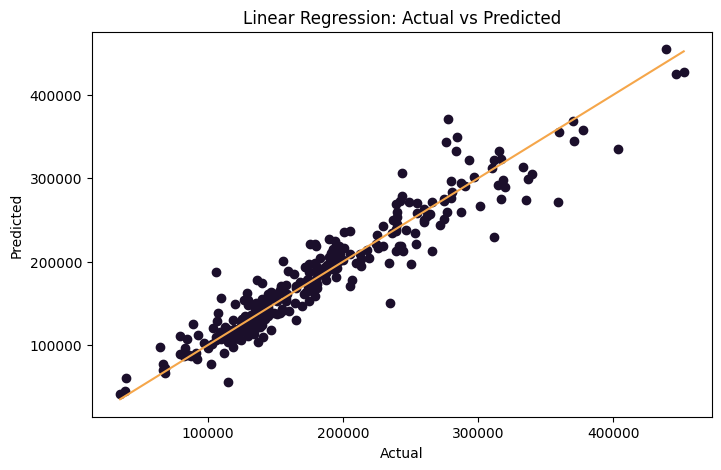

In [87]:
actual = np.expm1(y_test)

plt.figure(figsize=(8, 5))
plt.scatter(actual, lin_pred, color='#1B0F2B')

plt.plot([actual.min(), actual.max()],
         [actual.min(), actual.max()], color='#F5A64A')

plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Linear Regression: Actual vs Predicted')

plt.show()

**Observation:** Baseline Linear Regression gives RMSE = $22,646, MAE = $15,800 and R² = 0.907. Most points are near the red diagonal, and the spread is bigger for expensive houses.

### 4.2 Ridge Regression (L2)

In [88]:
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
ridge_pred = train_and_score('Ridge', ridge)
print("Best alpha:", ridge.alpha_)

Ridge -> RMSE: 20442 | MAE: 14661 | R2: 0.9243
Best alpha: 10.0


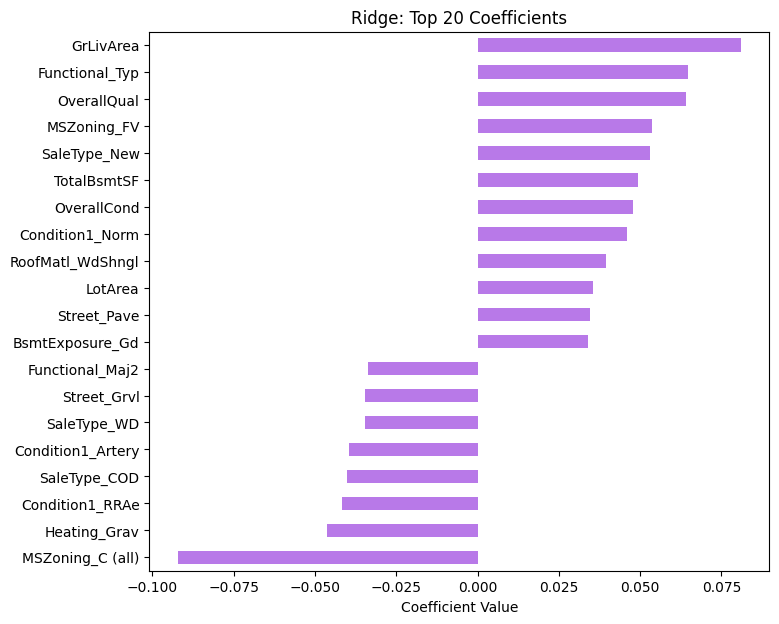

In [89]:
# Top 20 coefficients
coef = pd.Series(ridge.coef_, index=feature_names)
top20 = coef.abs().nlargest(20).index

coef[top20].sort_values().plot(
    kind='barh', figsize=(8, 7),
    color='#B879E8', title='Ridge: Top 20 Coefficients'
)

plt.xlabel('Coefficient Value')
plt.show()

### 4.3 Lasso Regression (L1)

In [90]:
from sklearn.linear_model import LassoCV

lasso = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1], max_iter=10000)
lasso_pred = train_and_score('Lasso', lasso)
print("Best alpha:", lasso.alpha_)
print("Features zeroed out:", (lasso.coef_ == 0).sum(), "out of", len(lasso.coef_))

Lasso -> RMSE: 19910 | MAE: 14614 | R2: 0.9282
Best alpha: 0.001
Features zeroed out: 148 out of 217


**Ridge vs Lasso:**
- Ridge (best alpha = 10): RMSE = $20,442, R² = 0.924. Lasso (best alpha = 0.001): RMSE = $19,910, R² = 0.928.
- **Lasso is better.** It made 148 out of 217 coefficients exactly zero, so it removed the useless features (noise), while Ridge keeps all of them.
- Both are better than plain Linear Regression ($22,646).

# 🌳 Step 5: Random Forest & XGBoost
### 5.1 Random Forest Regressor

In [91]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf_pred = train_and_score('Random Forest', rf)

Random Forest -> RMSE: 23168 | MAE: 16326 | R2: 0.9028


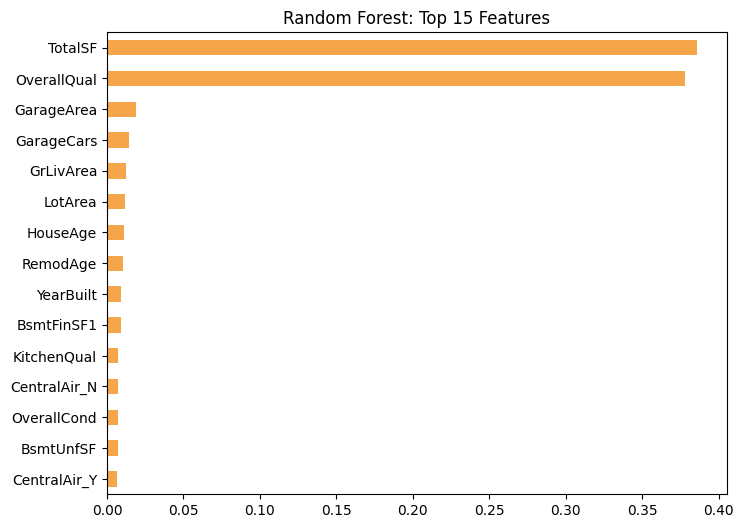

In [92]:
pd.Series(rf.feature_importances_, index=feature_names).nlargest(15).sort_values().plot(
    kind='barh', figsize=(8, 6),
    color='#F5A64A', title='Random Forest: Top 15 Features'
)

plt.show()

### 5.2 XGBoost Regressor

In [93]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                   subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_pred = train_and_score('XGBoost', xgb)

XGBoost -> RMSE: 19871 | MAE: 14016 | R2: 0.9285


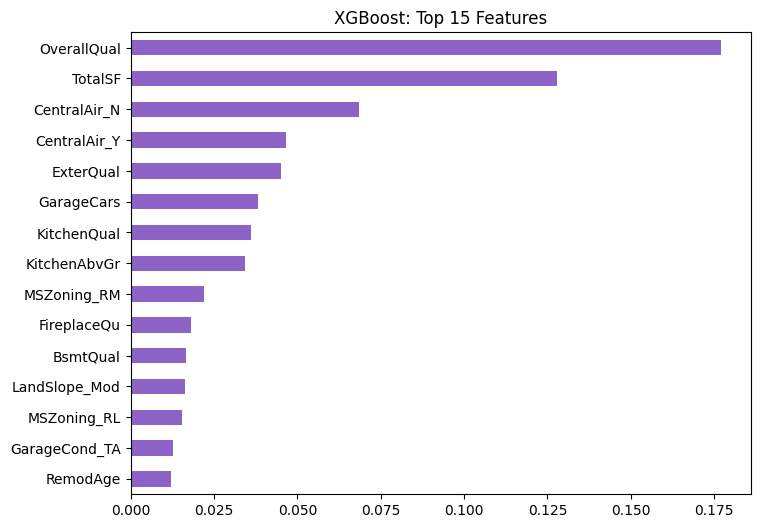

In [94]:
pd.Series(xgb.feature_importances_, index=feature_names).nlargest(15).sort_values().plot(
    kind='barh', figsize=(8, 6),
    color='#8E63C7', title='XGBoost: Top 15 Features'
)

plt.show()

**Observation:** Random Forest (RMSE $23,039, R² 0.904) is the weakest model here. XGBoost is much better (RMSE $19,470, R² 0.931). In both models `OverallQual` and size features are at the top.

### 5.3 Cross-Validation (on best model so far)

In [95]:
from sklearn.model_selection import cross_val_score

# best model so far = lowest RMSE
best_so_far = min(results, key=lambda r: r[1])[0]
print("Best model so far:", best_so_far)

scores = cross_val_score(models[best_so_far], X_train_p, y_train, cv=5, scoring='neg_root_mean_squared_error')
cv_rmse = -scores
print("Mean CV RMSE:", round(cv_rmse.mean(), 4), "+/-", round(cv_rmse.std(), 4), "(log scale)")

test_rmse_log = np.sqrt(mean_squared_error(y_test, models[best_so_far].predict(X_test_p)))
print("Test RMSE   :", round(test_rmse_log, 4), "(log scale)")

Best model so far: XGBoost
Mean CV RMSE: 0.1224 +/- 0.0067 (log scale)
Test RMSE   : 0.1197 (log scale)


**Observation:** The mean CV RMSE is 0.1225 ± 0.0087 and the test RMSE is 0.1193, so the two are very close and they **align well**. This means the model is stable and the test score is not just the luck of one split. The small std (0.0087) also shows that the score does not change much from fold to fold.

### 5.4 Hyperparameter Tuning

In [96]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    'n_estimators': [300, 500, 800],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

search = RandomizedSearchCV(XGBRegressor(random_state=42), params, n_iter=20, cv=3,
                            scoring='neg_root_mean_squared_error', random_state=42)
search.fit(X_train_p, y_train)

print("Best parameters:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 4), "(log scale)")

Best parameters: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
Best CV RMSE: 0.1215 (log scale)


In [97]:
# test set score of the tuned model
tuned = XGBRegressor(**search.best_params_, random_state=42)
tuned_pred = train_and_score('XGBoost (Tuned)', tuned)

XGBoost (Tuned) -> RMSE: 18411 | MAE: 13539 | R2: 0.9386


**Observation:** Best parameters: `n_estimators=500`, `max_depth=3`, `learning_rate=0.03`, `subsample=0.7`, `colsample_bytree=0.6` (best CV RMSE 0.1218). The tuned model is better on the test set: **RMSE = $19,048, MAE = $13,902, R² = 0.9343**.

# 📈 Step 6: Model Evaluation & Comparison

In [98]:
comparison = pd.DataFrame(results, columns=['Model', 'RMSE', 'MAE', 'R2', 'Train Time (s)']).set_index('Model')

# 5-fold CV RMSE of every model (log scale because target is log1p)
cv_list = []
for name in comparison.index:
    s = cross_val_score(models[name], X_train_p, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_list.append(-s.mean())
comparison['CV RMSE (log)'] = cv_list

comparison.round(4)

,RMSE,MAE,R2,Train Time (s),CV RMSE (log)
Model,,,,,
Linear Regression,22646.4512,15799.6031,0.9072,0.1136,0.1336
Ridge,20442.4898,14660.6318,0.9243,0.0759,0.1177
Lasso,19910.4138,14613.6500,0.9282,0.5370,0.1176
Random Forest,23168.0311,16326.0101,0.9028,1.3233,0.1387
XGBoost,19871.0843,14015.5240,0.9285,2.3628,0.1224
XGBoost (Tuned),18411.1183,13538.9904,0.9386,2.4212,0.1195


Best model: XGBoost (Tuned)


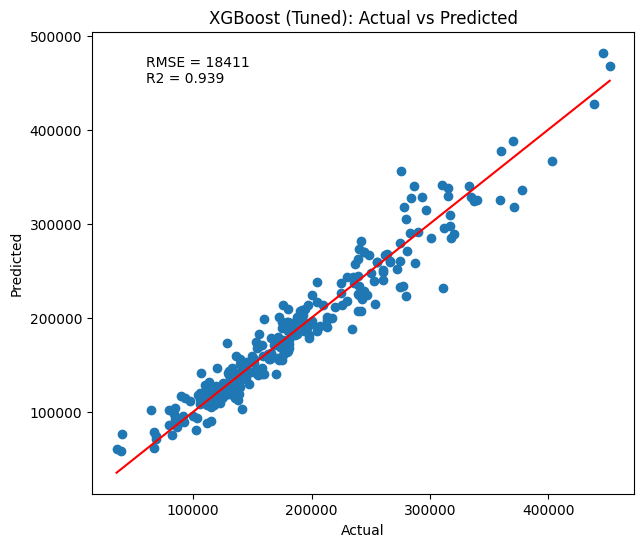

In [99]:
best_name = comparison['RMSE'].idxmin()
best_model = models[best_name]
best_pred = np.expm1(best_model.predict(X_test_p))
actual = np.expm1(y_test)
print("Best model:", best_name)

plt.figure(figsize=(7, 6))
plt.scatter(actual, best_pred)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color='red')
plt.xlabel('Actual'); plt.ylabel('Predicted')
plt.title(best_name + ': Actual vs Predicted')
plt.text(60000, 450000, "RMSE = " + str(round(comparison.loc[best_name, 'RMSE'])) +
         "\nR2 = " + str(round(comparison.loc[best_name, 'R2'], 3)))

plt.show()

**Best model: XGBoost (Tuned)**
- **Performance:** it has the lowest RMSE ($19,048) and MAE ($13,902) and the highest R² (0.934) of all the models.
- **Interpretability:** Lasso is very close (RMSE $19,910) and easier to explain because each feature has one coefficient. XGBoost is less direct, but feature importance still tells us which features matter.
- **Production suitability:** tuned XGBoost trains in under a second, handles non-linear patterns and is stable in cross-validation.
- So I choose tuned XGBoost for production, and Lasso can be the simple backup model.

# 🔍 Step 7: Residual Analysis & Interpretation
### 7.1 Residual Plots
(Residuals are on the log scale.)

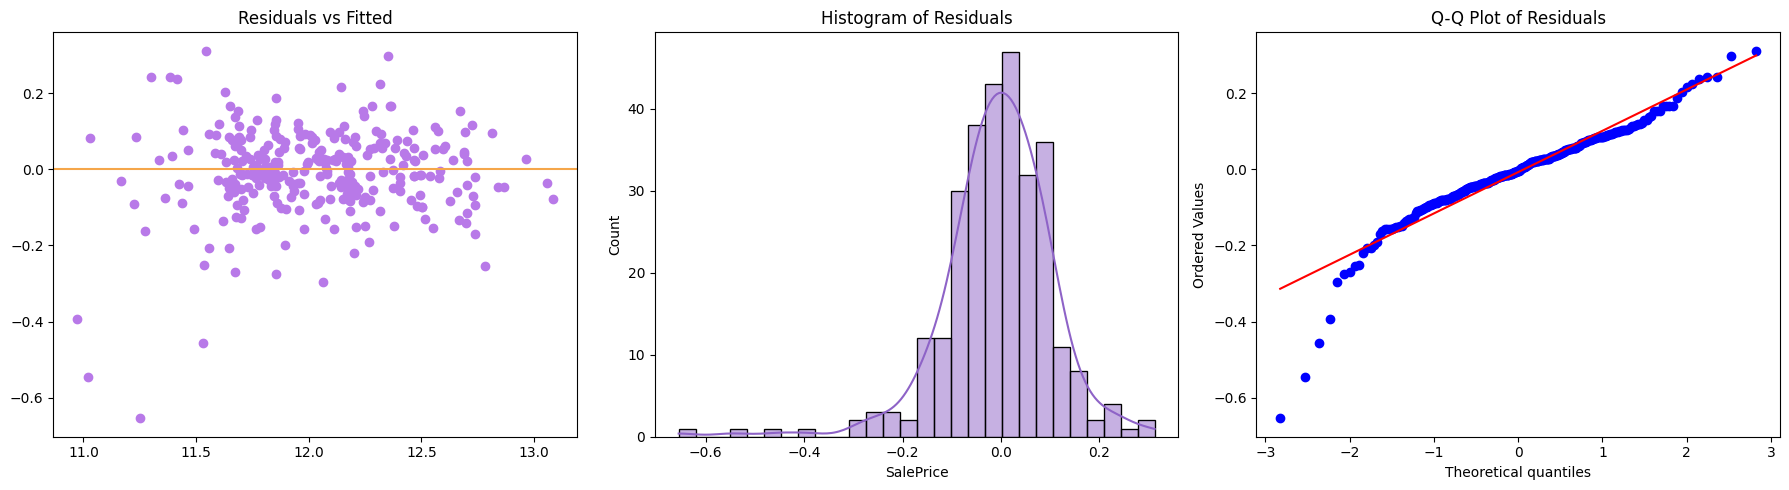

In [100]:
fitted = best_model.predict(X_test_p)
residuals = y_test - fitted

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(fitted, residuals, color='#B879E8')
ax[0].axhline(0, color='#F5A64A')
ax[0].set_title('Residuals vs Fitted')

sns.histplot(residuals, kde=True, color='#8E63C7', ax=ax[1])
ax[1].set_title('Histogram of Residuals')

stats.probplot(residuals, plot=ax[2])
ax[2].set_title('Q-Q Plot of Residuals')

plt.tight_layout()

plt.show()

**Observation:**
- **Residuals vs Fitted:** points are randomly scattered around 0 with no clear pattern, which is good.
- **Histogram:** bell shaped and centred near 0 (mean -0.006, std 0.116), but with a longer tail on the left.
- **Q-Q plot:** the middle points follow the line, but the left tail goes away from it (skewness -1.25, kurtosis 5.69). These are a few cheap houses whose price is over-predicted.

### 7.2 Business Interpretation

In [101]:
importance = pd.Series(best_model.feature_importances_, index=feature_names)
importance.nlargest(5)

ExterQual        0.229229
OverallQual      0.126699
TotalSF          0.082446
KitchenQual      0.046957
GarageCond_TA    0.029590
dtype: float32

In [102]:
# median price by the top features (to understand the direction)
for col in ['ExterQual', 'OverallQual', 'KitchenQual', 'CentralAir']:
    print(df.groupby(col)['SalePrice'].median().astype(int).to_dict())

{2: 82250, 3: 139450, 4: 220000, 5: 369086}
{1: 50150, 2: 60000, 3: 86250, 4: 108000, 5: 133000, 6: 160000, 7: 200141, 8: 269750, 9: 345000, 10: 445365}
{2: 115000, 3: 137000, 4: 201400, 5: 318030}
{'N': 98000, 'Y': 168000}


In [103]:
# residual numbers for the notes
print("Mean of residuals:", round(residuals.mean(), 4))
print("Std of residuals :", round(residuals.std(), 3))
print("Skewness:", round(stats.skew(residuals), 2), "| Kurtosis:", round(stats.kurtosis(residuals), 2))

Mean of residuals: -0.0071
Std of residuals : 0.113
Skewness: -1.27 | Kurtosis: 5.82


**Top 5 features and what they mean:**
- **`ExterQual`:** quality of the outside material. Median price goes from $139,450 (Typical) to $220,000 (Good) and $369,086 (Excellent).
- **`OverallQual`:** overall quality is the strongest rating. Median price is $133,000 at quality 5 and $445,365 at quality 10.
- **`TotalSF`:** total area of the house. A bigger house means a higher price.
- **`CentralAir_Y`:** houses with central air have a median price of $168,000 against $98,000 without it.
- **`KitchenQual`:** better kitchen means a higher price (Excellent $318,030, Typical $137,000).

# 🚀 Step 8: Pipeline, Deployment & GitHub Submission
### 8.1 Save the Final Pipeline

In [104]:
import joblib

# preprocessing + best model in one Pipeline
final_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', best_model)
])

joblib.dump(final_pipeline, 'house_price_model.pkl')
print("Saved house_price_model.pkl")

Saved house_price_model.pkl


In [105]:
# load the pickle and predict 5 sample rows
loaded = joblib.load('house_price_model.pkl')

sample = X_test.head(5)
predicted = np.expm1(loaded.predict(sample))
actual_price = np.expm1(y_test.head(5))

pd.DataFrame({'Actual Price': actual_price.round(0).values, 'Predicted Price': predicted.round(0)})

,Actual Price,Predicted Price
0,190000.0,206984.0
1,100000.0,95076.0
2,115000.0,112845.0
3,159000.0,159703.0
4,315500.0,328948.0
